In [3]:
import pandas as pd

file_path = "Raisin_Dataset.xlsx"
pandas_df = pd.read_excel(file_path)

print("Dataset shape:", pandas_df.shape)
pandas_df.head()

Dataset shape: (900, 8)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("RaisinClassification")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.3


In [6]:
spark_df = spark.createDataFrame(pandas_df)

print("Total rows:", spark_df.count())
print("Total columns:", len(spark_df.columns))

spark_df.show(5)
spark_df.printSchema()

Total rows: 900
Total columns: 8
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
| Area|MajorAxisLength|MinorAxisLength|Eccentricity|ConvexArea|     Extent|Perimeter|  Class|
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
|87524|    442.2460114|     253.291155| 0.819738392|     90546|0.758650579|  1184.04|Kecimen|
|75166|     406.690687|    243.0324363| 0.801805234|     78789| 0.68412957| 1121.786|Kecimen|
|90856|    442.2670483|    266.3283177| 0.798353619|     93717|0.637612812| 1208.575|Kecimen|
|45928|    286.5405586|    208.7600423| 0.684989217|     47336|0.699599385|  844.162|Kecimen|
|79408|    352.1907699|    290.8275329|  0.56401133|     81463|0.792771926| 1073.251|Kecimen|
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
only showing top 5 rows

root
 |-- Area: long (nullable = true)
 |-- MajorAxisLength: double (nullable = true)
 |-- Minor

In [7]:
from pyspark.sql.functions import col, sum

missing_values = spark_df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in spark_df.columns
])

missing_values.show()

+----+---------------+---------------+------------+----------+------+---------+-----+
|Area|MajorAxisLength|MinorAxisLength|Eccentricity|ConvexArea|Extent|Perimeter|Class|
+----+---------------+---------------+------------+----------+------+---------+-----+
|   0|              0|              0|           0|         0|     0|        0|    0|
+----+---------------+---------------+------------+----------+------+---------+-----+



In [8]:
total_rows = spark_df.count()
unique_rows = spark_df.dropDuplicates().count()

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Duplicate rows:", total_rows - unique_rows)

Total rows: 900
Unique rows: 900
Duplicate rows: 0


In [9]:
spark_df.groupBy("Class").count().show()

+-------+-----+
|  Class|count|
+-------+-----+
|Kecimen|  450|
|  Besni|  450|
+-------+-----+



In [10]:
spark_df.printSchema()

root
 |-- Area: long (nullable = true)
 |-- MajorAxisLength: double (nullable = true)
 |-- MinorAxisLength: double (nullable = true)
 |-- Eccentricity: double (nullable = true)
 |-- ConvexArea: long (nullable = true)
 |-- Extent: double (nullable = true)
 |-- Perimeter: double (nullable = true)
 |-- Class: string (nullable = true)



In [11]:
spark_df.describe().show()

26/10/18 07:41:23 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+------------------+------------------+-------------------+-----------------+--------------------+------------------+-------+
|summary|             Area|   MajorAxisLength|   MinorAxisLength|       Eccentricity|       ConvexArea|              Extent|         Perimeter|  Class|
+-------+-----------------+------------------+------------------+-------------------+-----------------+--------------------+------------------+-------+
|  count|              900|               900|               900|                900|              900|                 900|               900|    900|
|   mean|87804.12777777777|430.92995049844444|254.48813290322227| 0.7815421500333333|         91186.09|  0.6995079264077777|1165.9066355555556|   NULL|
| stddev|39002.11139007148|116.03512062468941|49.988901705717616|0.09031840993160663|40769.29013198777|0.053468200288159275| 273.7643154160195|   NULL|
|    min|            25387|        225.629541|       143.7108718|        0.348729642|   

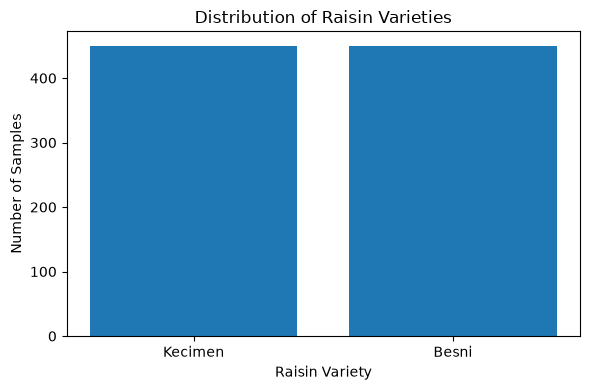

In [12]:
import matplotlib.pyplot as plt

class_counts = (
    spark_df.groupBy("Class")
    .count()
    .toPandas()
)

plt.figure(figsize=(6, 4))
plt.bar(class_counts["Class"], class_counts["count"])
plt.title("Distribution of Raisin Varieties")
plt.xlabel("Raisin Variety")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

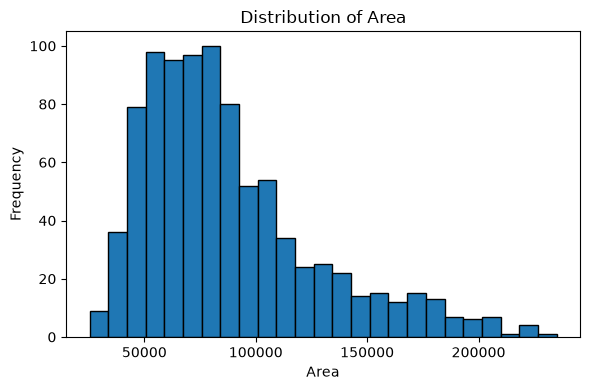

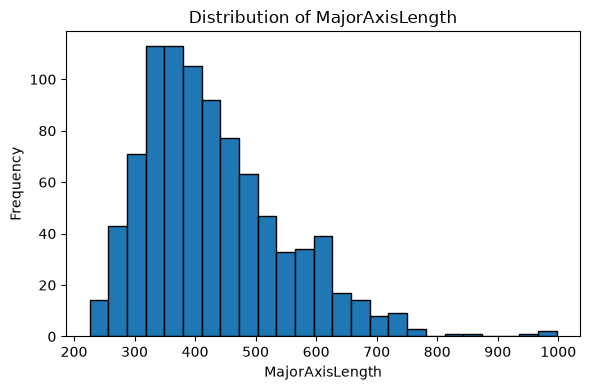

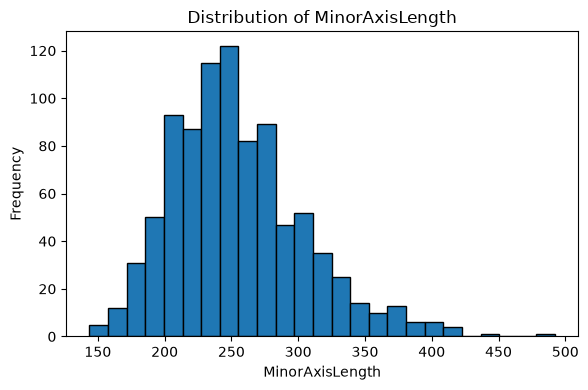

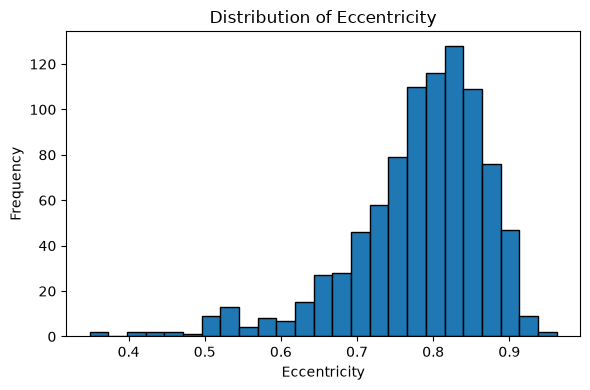

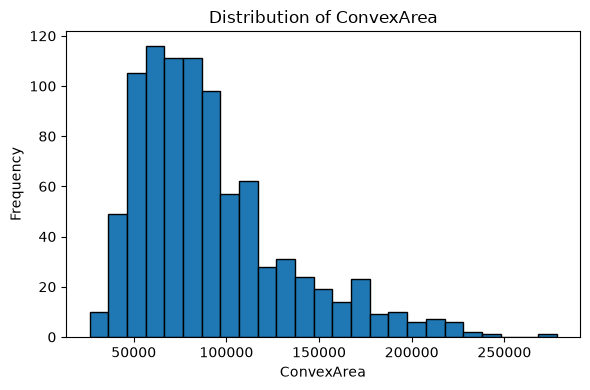

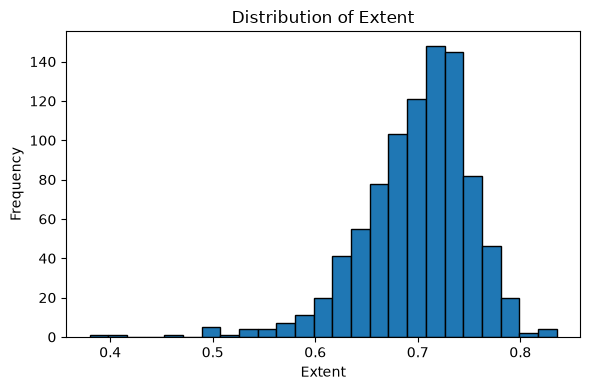

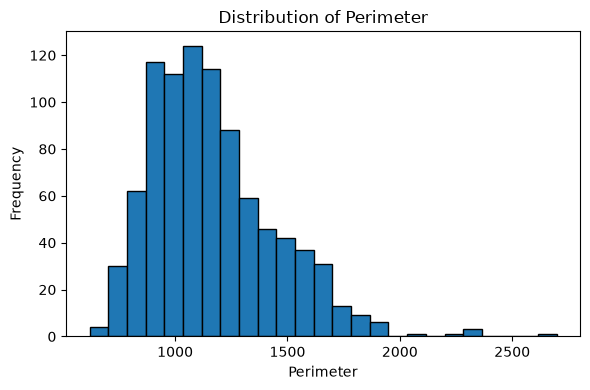

In [13]:
feature_columns = [
    "Area",
    "MajorAxisLength",
    "MinorAxisLength",
    "Eccentricity",
    "ConvexArea",
    "Extent",
    "Perimeter"
]

for feature in feature_columns:
    values = spark_df.select(feature).toPandas()[feature]

    plt.figure(figsize=(6, 4))
    plt.hist(values, bins=25, edgecolor="black")
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

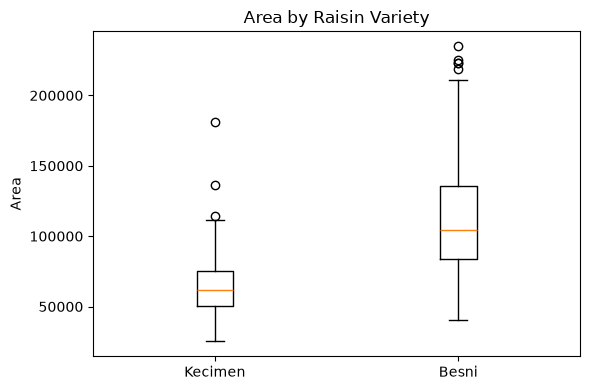

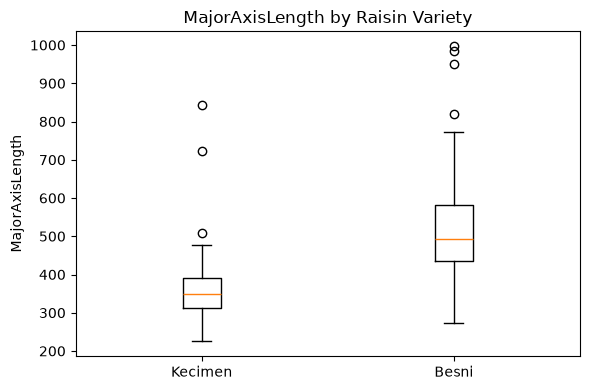

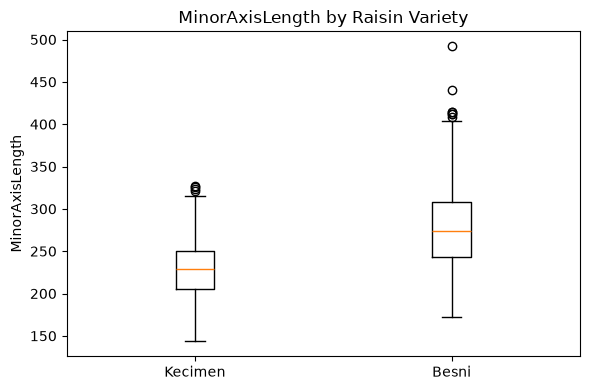

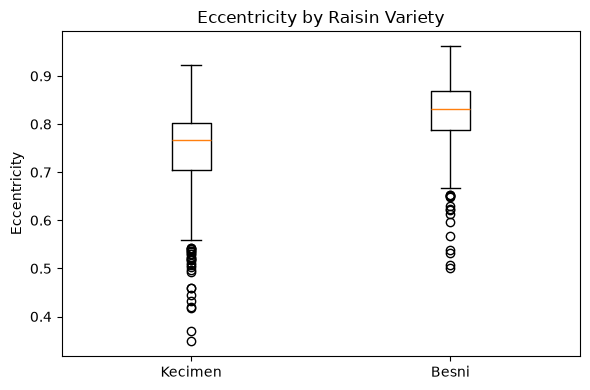

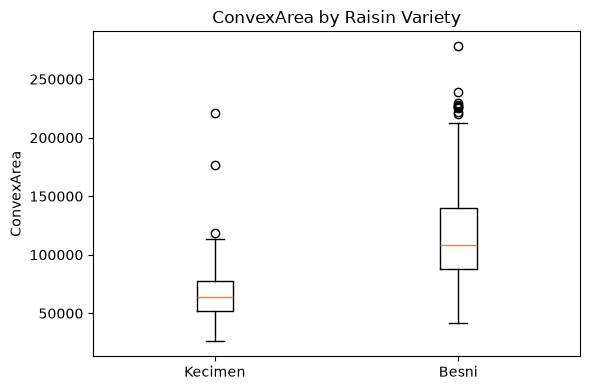

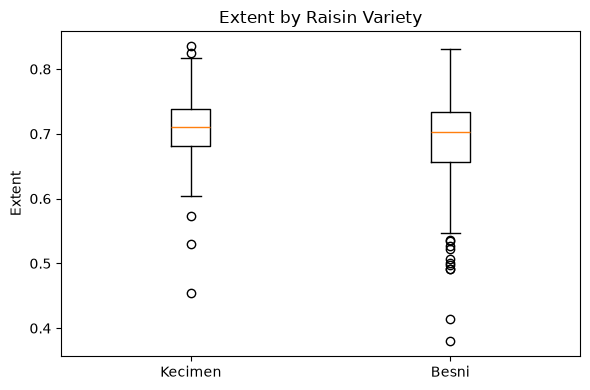

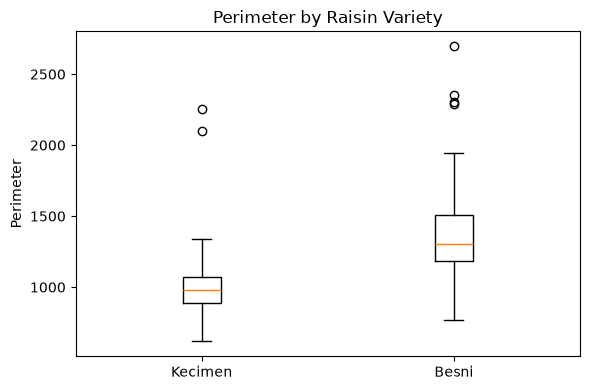

In [15]:
import matplotlib.pyplot as plt

for feature in feature_columns:
    kecimen = (
        spark_df.filter(spark_df["Class"] == "Kecimen")
        .select(feature)
        .toPandas()[feature]
    )

    besni = (
        spark_df.filter(spark_df["Class"] == "Besni")
        .select(feature)
        .toPandas()[feature]
    )

    plt.figure(figsize=(6, 4))
    plt.boxplot(
        [kecimen, besni],
        tick_labels=["Kecimen", "Besni"]
    )
    plt.title(f"{feature} by Raisin Variety")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

In [17]:
from pyspark.sql.functions import col, count, when

for feature in feature_columns:
    q1, q3 = spark_df.approxQuantile(
        feature, [0.25, 0.75], 0.01
    )

    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = spark_df.filter(
        (col(feature) < lower_bound) |
        (col(feature) > upper_bound)
    ).count()

    print(f"\nFeature: {feature}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {outlier_count}")


Feature: Area
Lower bound: -9675.50
Upper bound: 172768.50
Potential outliers: 42

Feature: MajorAxisLength
Lower bound: 123.58
Upper bound: 710.51
Potential outliers: 19

Feature: MinorAxisLength
Lower bound: 128.55
Upper bound: 367.19
Potential outliers: 31

Feature: Eccentricity
Lower bound: 0.59
Upper bound: 0.99
Potential outliers: 42

Feature: ConvexArea
Lower bound: -10482.00
Upper bound: 179062.00
Potential outliers: 42



Feature: Extent
Lower bound: 0.57
Upper bound: 0.83
Potential outliers: 20

Feature: Perimeter
Lower bound: 447.49
Upper bound: 1810.52
Potential outliers: 18


Random Forest is generally robust to extreme feature values. Logistic Regression can be more sensitive to them, so we'll scale its features and compare both models fairly.

In [18]:
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col

In [19]:
label_indexer = StringIndexer(
    inputCol="Class",
    outputCol="label"
)

label_model = label_indexer.fit(spark_df)
spark_df = label_model.transform(spark_df)

spark_df.select("Class", "label").distinct().show()

+-------+-----+
|  Class|label|
+-------+-----+
|Kecimen|  1.0|
|  Besni|  0.0|
+-------+-----+



In [20]:
feature_columns = [
    "Area",
    "MajorAxisLength",
    "MinorAxisLength",
    "Eccentricity",
    "ConvexArea",
    "Extent",
    "Perimeter"
]

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

spark_df = assembler.transform(spark_df)

spark_df.select("features", "label").show(5, truncate=False)

+--------------------------------------------------------------------------+-----+
|features                                                                  |label|
+--------------------------------------------------------------------------+-----+
|[87524.0,442.2460114,253.291155,0.819738392,90546.0,0.758650579,1184.04]  |1.0  |
|[75166.0,406.690687,243.0324363,0.801805234,78789.0,0.68412957,1121.786]  |1.0  |
|[90856.0,442.2670483,266.3283177,0.798353619,93717.0,0.637612812,1208.575]|1.0  |
|[45928.0,286.5405586,208.7600423,0.684989217,47336.0,0.699599385,844.162] |1.0  |
|[79408.0,352.1907699,290.8275329,0.56401133,81463.0,0.792771926,1073.251] |1.0  |
+--------------------------------------------------------------------------+-----+
only showing top 5 rows



Now we'll split the data before fitting any scaling or other learned preprocessing transformations, so information from the test set doesn't leak into training.

In [21]:
train_df, test_df = spark_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 723
Testing records: 177


Logistic Regression

In [22]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(train_df)

train_scaled = scaler_model.transform(train_df)
test_scaled = scaler_model.transform(test_df)

train_scaled.select("scaledFeatures", "label").show(
    5, truncate=False
)

+----------------------------------------------------------------------------------------------------------------------------------------------+-----+
|scaledFeatures                                                                                                                                |label|
+----------------------------------------------------------------------------------------------------------------------------------------------+-----+
|[-1.6131233710671478,-1.796933495757813,-2.178212549191135,-0.18085608055694746,-1.6078367740053716,-0.3867330078705393,-2.0097286457543]     |1.0  |
|[-1.4036565564523213,-1.4854937504627164,-1.7227628091881255,-0.18314761295239704,-1.3714344790637585,-0.32411978942317277,-1.527320078667652]|1.0  |
|[-1.2003625838920529,-1.4945240890154017,-0.9701201321366162,-1.9269687121937236,-1.192204567207455,2.3000515311898386,-1.385104346069412]    |1.0  |
|[-1.1924992539719315,-1.0868970246954033,-1.5772489824307612,0.434431711840947,-1.17447745570

In [23]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="scaledFeatures",
    labelCol="label",
    maxIter=100
)

lr_model = lr.fit(train_scaled)

print("Logistic Regression model trained successfully!")

26/10/18 08:28:48 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


Logistic Regression model trained successfully!


In [24]:
lr_predictions = lr_model.transform(test_scaled)

lr_predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+-----------------------------------------+
|label|prediction|probability                              |
+-----+----------+-----------------------------------------+
|1.0  |1.0       |[0.026068038975331376,0.9739319610246686]|
|1.0  |1.0       |[0.07193682271657315,0.9280631772834269] |
|1.0  |1.0       |[0.02916439397067627,0.9708356060293237] |
|1.0  |1.0       |[0.059392480124514285,0.9406075198754857]|
|1.0  |1.0       |[0.13593791514413825,0.8640620848558618] |
|1.0  |1.0       |[0.11042915116351647,0.8895708488364835] |
|1.0  |1.0       |[0.24327465477557733,0.7567253452244227] |
|1.0  |1.0       |[0.05013233168393226,0.9498676683160677] |
|1.0  |1.0       |[0.1580483568846711,0.8419516431153289]  |
|1.0  |1.0       |[0.20430819151546903,0.795691808484531]  |
+-----+----------+-----------------------------------------+
only showing top 10 rows



In [25]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = ["accuracy", "weightedPrecision", "weightedRecall", "f1"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(lr_predictions)

    print(f"{metric}: {score:.4f}")

accuracy: 0.8983
weightedPrecision: 0.8988
weightedRecall: 0.8983
f1: 0.8984


In [26]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="accuracy"
    ).evaluate(lr_predictions),
    "Precision": MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="weightedPrecision"
    ).evaluate(lr_predictions),
    "Recall": MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="weightedRecall"
    ).evaluate(lr_predictions),
    "F1-score": MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="f1"
    ).evaluate(lr_predictions)
}

print(lr_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.8983050847457628, 'Precision': 0.8988129901177377, 'Recall': 0.8983050847457628, 'F1-score': 0.8984433645450594}


Random Forest Classifier

In [27]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=5,
    seed=42
)

rf_model = rf.fit(train_df)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [28]:
rf_predictions = rf_model.transform(test_df)

rf_predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|1.0  |1.0       |[0.06324736914566106,0.9367526308543389]|
|1.0  |1.0       |[0.10550603361474822,0.8944939663852517]|
|1.0  |1.0       |[0.06739741865439841,0.9326025813456016]|
|1.0  |1.0       |[0.06892738358176972,0.9310726164182302]|
|1.0  |1.0       |[0.08728624170707351,0.9127137582929264]|
|1.0  |1.0       |[0.12252971469890923,0.8774702853010908]|
|1.0  |1.0       |[0.1230986201041747,0.8769013798958253] |
|1.0  |1.0       |[0.20436038237113038,0.7956396176288697]|
|1.0  |1.0       |[0.1493630449354802,0.8506369550645199] |
|1.0  |1.0       |[0.16653041498636176,0.8334695850136382]|
+-----+----------+----------------------------------------+
only showing top 10 rows



In [29]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

rf_results = {
    "Model": "Random Forest"
}

metrics = {
    "Accuracy": "accuracy",
    "Precision": "weightedPrecision",
    "Recall": "weightedRecall",
    "F1-score": "f1"
}

for name, metric_name in metrics.items():
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    rf_results[name] = evaluator.evaluate(rf_predictions)

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.8700564971751412, 'Precision': 0.8702919020715632, 'Recall': 0.8700564971751413, 'F1-score': 0.869460913924348}


Comapre Both Models

In [31]:
import pandas as pd

comparison_df = pd.DataFrame([
    lr_results,
    rf_results
])

comparison_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.898305,0.898813,0.898305,0.898443
1,Random Forest,0.870056,0.870292,0.870056,0.869461


Logistic Regression performs better than Random Forest on the test set.

In [32]:
from pyspark.sql.functions import col, sum, when

def show_confusion_matrix(predictions, model_name):
    print(f"\n{model_name} Confusion Matrix")

    matrix = (
        predictions
        .groupBy("label")
        .pivot("prediction", [0.0, 1.0])
        .count()
        .fillna(0)
        .orderBy("label")
    )

    matrix.show()

show_confusion_matrix(lr_predictions, "Logistic Regression")
show_confusion_matrix(rf_predictions, "Random Forest")


Logistic Regression Confusion Matrix
+-----+---+---+
|label|0.0|1.0|
+-----+---+---+
|  0.0| 69|  8|
|  1.0| 10| 90|
+-----+---+---+


Random Forest Confusion Matrix
+-----+---+---+
|label|0.0|1.0|
+-----+---+---+
|  0.0| 63| 14|
|  1.0|  9| 91|
+-----+---+---+



Tuning Logistic Regression

In [33]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# 1. Scale the features
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withMean=True,
    withStd=True
)

# 2. Define Logistic Regression
lr_tune = LogisticRegression(
    featuresCol="scaledFeatures",
    labelCol="label",
    maxIter=100
)

# 3. Create a pipeline
lr_pipeline = Pipeline(
    stages=[scaler, lr_tune]
)

# 4. Define hyperparameter values
param_grid = (
    ParamGridBuilder()
    .addGrid(lr_tune.regParam, [0.001, 0.01, 0.1])
    .addGrid(lr_tune.elasticNetParam, [0.0, 0.5, 1.0])
    .build()
)

# 5. Evaluate using accuracy
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

# 6. Configure cross-validation
cross_validator = CrossValidator(
    estimator=lr_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    numFolds=3,
    seed=42,
    parallelism=2
)

# 7. Train and select the best configuration
lr_cv_model = cross_validator.fit(train_df)

print("Best Logistic Regression parameters:")
print("Regularization:", lr_cv_model.bestModel.stages[-1].getRegParam())
print("Elastic Net:", lr_cv_model.bestModel.stages[-1].getElasticNetParam())

Best Logistic Regression parameters:
Regularization: 0.001
Elastic Net: 1.0


In [34]:
tuned_lr_predictions = lr_cv_model.transform(test_df)

for metric_name in [
    "accuracy",
    "weightedPrecision",
    "weightedRecall",
    "f1"
]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    score = evaluator.evaluate(tuned_lr_predictions)
    print(f"{metric_name}: {score:.4f}")

accuracy: 0.8870
weightedPrecision: 0.8869
weightedRecall: 0.8870
f1: 0.8868


Tuned Logistic Regression didn't improve the previous model

Tuning Random Forest Model

In [35]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

rf_tune = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    seed=42
)

rf_pipeline = Pipeline(stages=[rf_tune])

rf_param_grid = (
    ParamGridBuilder()
    .addGrid(rf_tune.numTrees, [50, 100])
    .addGrid(rf_tune.maxDepth, [3, 5, 8])
    .addGrid(rf_tune.minInstancesPerNode, [1, 5])
    .build()
)

rf_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

rf_cv = CrossValidator(
    estimator=rf_pipeline,
    estimatorParamMaps=rf_param_grid,
    evaluator=rf_evaluator,
    numFolds=3,
    seed=42,
    parallelism=2
)

rf_cv_model = rf_cv.fit(train_df)

best_rf = rf_cv_model.bestModel.stages[-1]

print("Best number of trees:", best_rf.getNumTrees)
print("Best maximum depth:", best_rf.getMaxDepth())
print("Best minimum instances per node:",
      best_rf.getMinInstancesPerNode())

26/10/18 08:52:08 WARN DAGScheduler: Broadcasting large task binary with size 1040.0 KiB
26/10/18 08:52:14 WARN DAGScheduler: Broadcasting large task binary with size 1056.8 KiB
26/10/18 08:52:21 WARN DAGScheduler: Broadcasting large task binary with size 1056.6 KiB


Best number of trees: 50
Best maximum depth: 5
Best minimum instances per node: 5


In [36]:
tuned_rf_predictions = rf_cv_model.transform(test_df)

for metric_name in [
    "accuracy",
    "weightedPrecision",
    "weightedRecall",
    "f1"
]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    score = evaluator.evaluate(tuned_rf_predictions)
    print(f"{metric_name}: {score:.4f}")

accuracy: 0.8644
weightedPrecision: 0.8650
weightedRecall: 0.8644
f1: 0.8646


Tuned Random Forest doesn't improve the previous model

Tuned both models. No model outperformed its baseline model and Logistic regression still worked better than Random Forest

Feature importance from the best Random Forest model:

           Feature  Importance
1  MajorAxisLength    0.423744
6        Perimeter    0.256623
4       ConvexArea    0.115100
0             Area    0.084232
3     Eccentricity    0.055030
2  MinorAxisLength    0.032727
5           Extent    0.032544


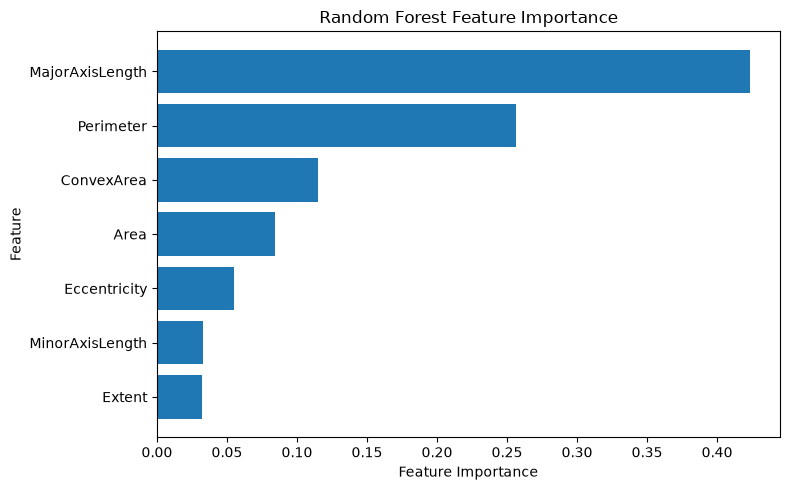

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.featureImportances.toArray()
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Feature Importance Analysis

The Random Forest model identified **MajorAxisLength** as the most important feature, with an importance score of 0.4237. **Perimeter** ranked second with 0.2566, followed by ConvexArea with 0.1151 and Area with 0.0842.

MajorAxisLength and Perimeter together contributed approximately 68.04% of the total feature importance. In comparison, MinorAxisLength and Extent had the lowest importance scores.

These results suggest that the length and boundary measurements of raisins are particularly useful for distinguishing between the Kecimen and Besni varieties. However, feature importance indicates the model's reliance on features, not a causal relationship.

In [38]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate tuned Logistic Regression
tuned_lr_results = {"Model": "Tuned Logistic Regression"}

# Evaluate tuned Random Forest
tuned_rf_results = {"Model": "Tuned Random Forest"}

metrics = {
    "Accuracy": "accuracy",
    "Precision": "weightedPrecision",
    "Recall": "weightedRecall",
    "F1-score": "f1"
}

for name, metric_name in metrics.items():
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    tuned_lr_results[name] = evaluator.evaluate(tuned_lr_predictions)
    tuned_rf_results[name] = evaluator.evaluate(rf_cv_model.transform(test_df))

# Combine all model results
results_df = pd.DataFrame([
    lr_results,
    rf_results,
    tuned_lr_results,
    tuned_rf_results
])

print(results_df.round(4))

                       Model  Accuracy  Precision  Recall  F1-score
0        Logistic Regression    0.8983     0.8988  0.8983    0.8984
1              Random Forest    0.8701     0.8703  0.8701    0.8695
2  Tuned Logistic Regression    0.8870     0.8869  0.8870    0.8868
3        Tuned Random Forest    0.8644     0.8650  0.8644    0.8646


Model Comparision Chart

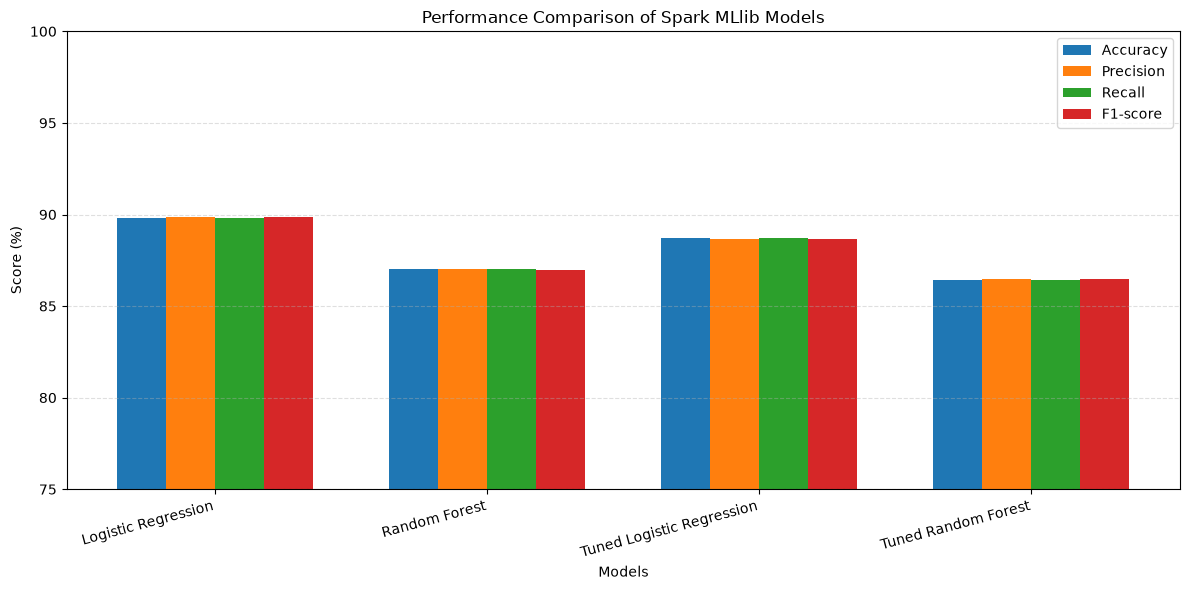

In [39]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

x = np.arange(len(results_df))
width = 0.18

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        results_df[metric] * 100,
        width,
        label=metric
    )

plt.xlabel("Models")
plt.ylabel("Score (%)")
plt.title("Performance Comparison of Spark MLlib Models")
plt.xticks(x, results_df["Model"], rotation=15, ha="right")
plt.ylim(75, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Model Performance Comparison

The baseline Logistic Regression model achieved the best overall performance, with 89.83% accuracy and an F1-score of 89.84%. The baseline Random Forest model achieved 87.01% accuracy. After hyperparameter tuning, Logistic Regression achieved 88.70% accuracy, while Random Forest achieved 86.44%.

In this experiment, tuning did not improve test-set performance. Therefore, baseline Logistic Regression was selected as the best-performing model for classifying Kecimen and Besni raisins.

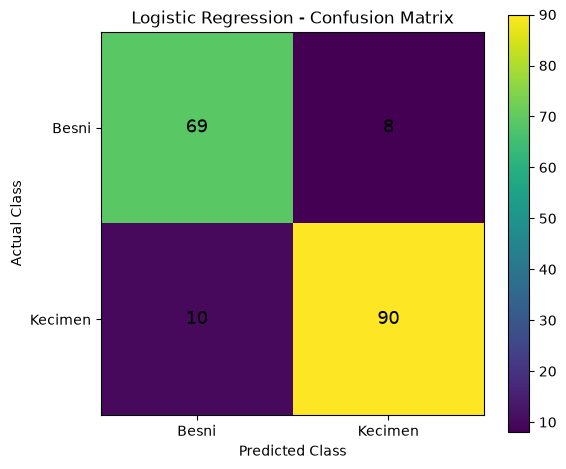

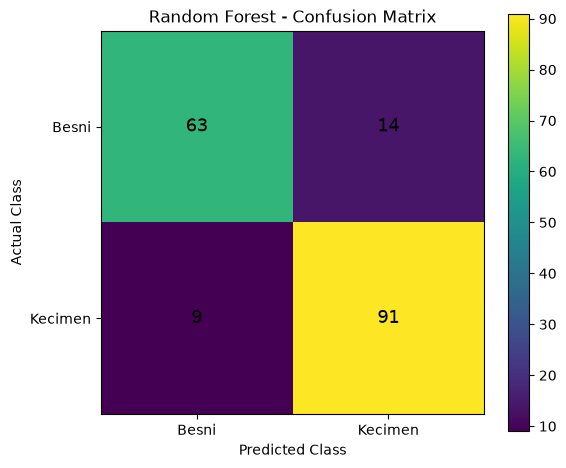

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Confusion matrices from your Spark MLlib results
lr_matrix = np.array([
    [69, 8],
    [10, 90]
])

rf_matrix = np.array([
    [63, 14],
    [9, 91]
])

class_names = ["Besni", "Kecimen"]

def plot_confusion_matrix(matrix, model_name):
    plt.figure(figsize=(6, 5))
    plt.imshow(matrix, interpolation="nearest")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.colorbar()

    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names)
    plt.yticks(tick_marks, class_names)

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            plt.text(
                j, i, str(matrix[i, j]),
                ha="center", va="center", fontsize=13
            )

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(lr_matrix, "Logistic Regression")
plot_confusion_matrix(rf_matrix, "Random Forest")

### Confusion Matrix Analysis

The confusion matrices show that Logistic Regression correctly classified 159 out of 177 test records, while Random Forest correctly classified 154. Logistic Regression made 18 incorrect predictions, compared with 23 for Random Forest.

Both models classified Kecimen raisins relatively well. However, Logistic Regression identified more Besni samples correctly. Overall, the confusion matrices support the earlier evaluation results, indicating that baseline Logistic Regression performed better on the test dataset.

# Final Conclusion

This project used Apache Spark MLlib to classify raisins into two varieties: Kecimen and Besni. The UCI Raisin dataset containing 900 records and seven numerical features was explored and preprocessed before training Logistic Regression and Random Forest classification models.

The baseline Logistic Regression model achieved the best performance, with **89.83% accuracy and an F1-score of 89.84%**. The baseline Random Forest model achieved 87.01% accuracy. Hyperparameter tuning did not improve the test-set performance of either model in this experiment.

The Random Forest feature importance analysis identified MajorAxisLength and Perimeter as the most influential features. The confusion matrices also showed that Logistic Regression made fewer incorrect predictions than Random Forest.

Overall, baseline Logistic Regression was selected as the best-performing model for this dataset. This project provided practical experience with data exploration, preprocessing, distributed machine learning workflows, model evaluation, hyperparameter tuning, and visualization using PySpark and Matplotlib.

One limitation is that the evaluation used a single train-test split. Further testing with different splits or additional validation could help assess how well the model generalizes to unseen raisin samples.